In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Sample - Superstore.csv to Sample - Superstore.csv


In [51]:
df = pd.read_csv('Sample - Superstore.csv', encoding='windows-1252')
df = df.rename(columns={
    'Order ID': 'Order_ID', 'Order Date': 'Order_Date',
    'Product Name': 'Product_Name', 'Sales': 'Revenue'
})
df['Unit_Price'] = df['Revenue'] / df['Quantity']

In [ ]:
sns.set_theme(style = "whitegrid",palette = "muted")
plt.rcParams['figure.figsize']=(12,6)

In [ ]:
np.random.seed(42)

n_records = 5000

In [ ]:
categories = {
    'Electronics':[('smartphone pro',850),('wireless earbuds',120),('4k monitor',420),('USB-C Hub',35)],
    'Officesupplies':[('printer paper box',28),('Gel pens pack',12),('whiteboard',85),('stapler set',18),('Binder Pack',22)],
    'Approval':[('cotton -shirt',25),('Denim Jacket',95),('Running Shoes',110),('wool sweater',75),('Baseball Cap',20)]
}

In [ ]:
records = []
dates = pd.date_range(start = '2024-01-01',end = '2025-12-31',freq = 'D')

In [44]:
np.random.seed(42)
records = []

for i in range(n_records):
    # 1. Select category and product
    cat = np.random.choice(list(categories.keys()), p=[0.40, 0.35, 0.25])
    prod, base_price = categories[cat][np.random.randint(0, len(categories[cat]))]

    # 2. Select random date
    date = np.random.choice(dates)

    # 3. Calculate quantity with holiday season multiplier
    month = pd.to_datetime(date).month
    qty_multiplier = 2 if month in [11, 12] else 1
    qty = np.random.randint(1, 6) * qty_multiplier

    # 4. Calculate prices
    discount = np.random.choice([0.0, 0.05, 0.10, 0.20], p=[0.5, 0.2, 0.2, 0.1])
    unit_price = round(base_price * (1 - discount), 2)
    revenue = round(unit_price * qty, 2)

    # 5. Append record
    records.append([f"ORD-{10000+i}", date, cat, prod, unit_price, qty, discount, revenue])

In [18]:
month = pd.to_datetime(date).month
qty_multiplier = 2 if month in [11,12] else 1
qty = np.random.randint(1,6)*qty_multiplier

In [20]:
discount = np.random.choice([0.0,0.05,0.10,0.20],p=[0.5,0.2,0.2,0.1])
unit_price = round(base_price*(1-discount),2)
revenue = round(unit_price*qty,2)

In [21]:
records.append([f"ORD-{10000+i}",date,cat,prod,unit_price,qty,discount,revenue])

In [23]:
df = pd.DataFrame(records, columns=['Order_ID', 'Order_Date', 'Category', 'Product_Name', 'Unit_Price', 'Quantity', 'Discount', 'Revenue'])

In [24]:
required_attributes = ['Order_Date', 'Category', 'Product_Name', 'Unit_Price', 'Quantity', 'Revenue']
missing_cols = [col for col in required_attributes if col not in df.columns]

In [25]:
assert len(missing_cols)==0,f"missing required attributes:{missing_cols}"

In [26]:
print("Attributes verification passed! All required product and sales fields are present.\n")

Attributes verification passed! All required product and sales fields are present.



In [27]:
df['Order_Date'] = pd.to_datetime(df['Order_Date'])
df['YearMonth'] = df['Order_Date'].dt.to_period('M').astype(str)
df['Price_Tier'] = pd.cut(df['Unit_Price'], bins=[0, 50, 250, 2000], labels=['Budget (<$50)', 'Mid-Range ($50-$250)', 'Premium (>$250)'])

In [28]:
cat_summary = df.groupby('Category').agg(
    Total_Revenue=('Revenue', 'sum'),
    Total_Quantity=('Quantity', 'sum'),
    Avg_Order_Value=('Revenue', 'mean'),
    Order_Count=('Order_ID', 'count')
).sort_values(by='Total_Revenue', ascending=False)

In [29]:
print("--- CATEGORY PERFORMANCE SUMMARY ---")
print(cat_summary.to_string(), "\n")

--- CATEGORY PERFORMANCE SUMMARY ---
             Total_Revenue  Total_Quantity  Avg_Order_Value  Order_Count
Category                                                                
Electronics           35.0               1             35.0            1 



In [30]:
prod_summary = df.groupby(['Category', 'Product_Name']).agg(
    Total_Revenue=('Revenue', 'sum'),
    Total_Quantity=('Quantity', 'sum'),
    Avg_Price=('Unit_Price', 'mean')
).reset_index().sort_values(by='Total_Revenue', ascending=False)

In [31]:
prod_summary['Cum_Revenue'] = prod_summary['Total_Revenue'].cumsum()
prod_summary['Cum_Perc'] = 100 * prod_summary['Cum_Revenue'] / prod_summary['Total_Revenue'].sum()

In [32]:
def assign_abc(perc):
    if perc <= 80: return 'Class A (Top Drivers)'
    elif perc <= 95: return 'Class B (Moderate)'
    else: return 'Class C (Low Performers)'

In [33]:
prod_summary['ABC_Class'] = prod_summary['Cum_Perc'].apply(assign_abc)

In [34]:
print("--- TOP 5 HIGH-PERFORMING PRODUCTS ---")
print(prod_summary[['Product_Name', 'Category', 'Total_Revenue', 'Total_Quantity', 'ABC_Class']].head(5).to_string(index=False), "\n")

--- TOP 5 HIGH-PERFORMING PRODUCTS ---
Product_Name    Category  Total_Revenue  Total_Quantity                ABC_Class
   USB-C Hub Electronics           35.0               1 Class C (Low Performers) 



In [35]:
print("--- BOTTOM 5 LOW-PERFORMING PRODUCTS ---")
print(prod_summary[['Product_Name', 'Category', 'Total_Revenue', 'Total_Quantity', 'ABC_Class']].tail(5).to_string(index=False), "\n")

--- BOTTOM 5 LOW-PERFORMING PRODUCTS ---
Product_Name    Category  Total_Revenue  Total_Quantity                ABC_Class
   USB-C Hub Electronics           35.0               1 Class C (Low Performers) 



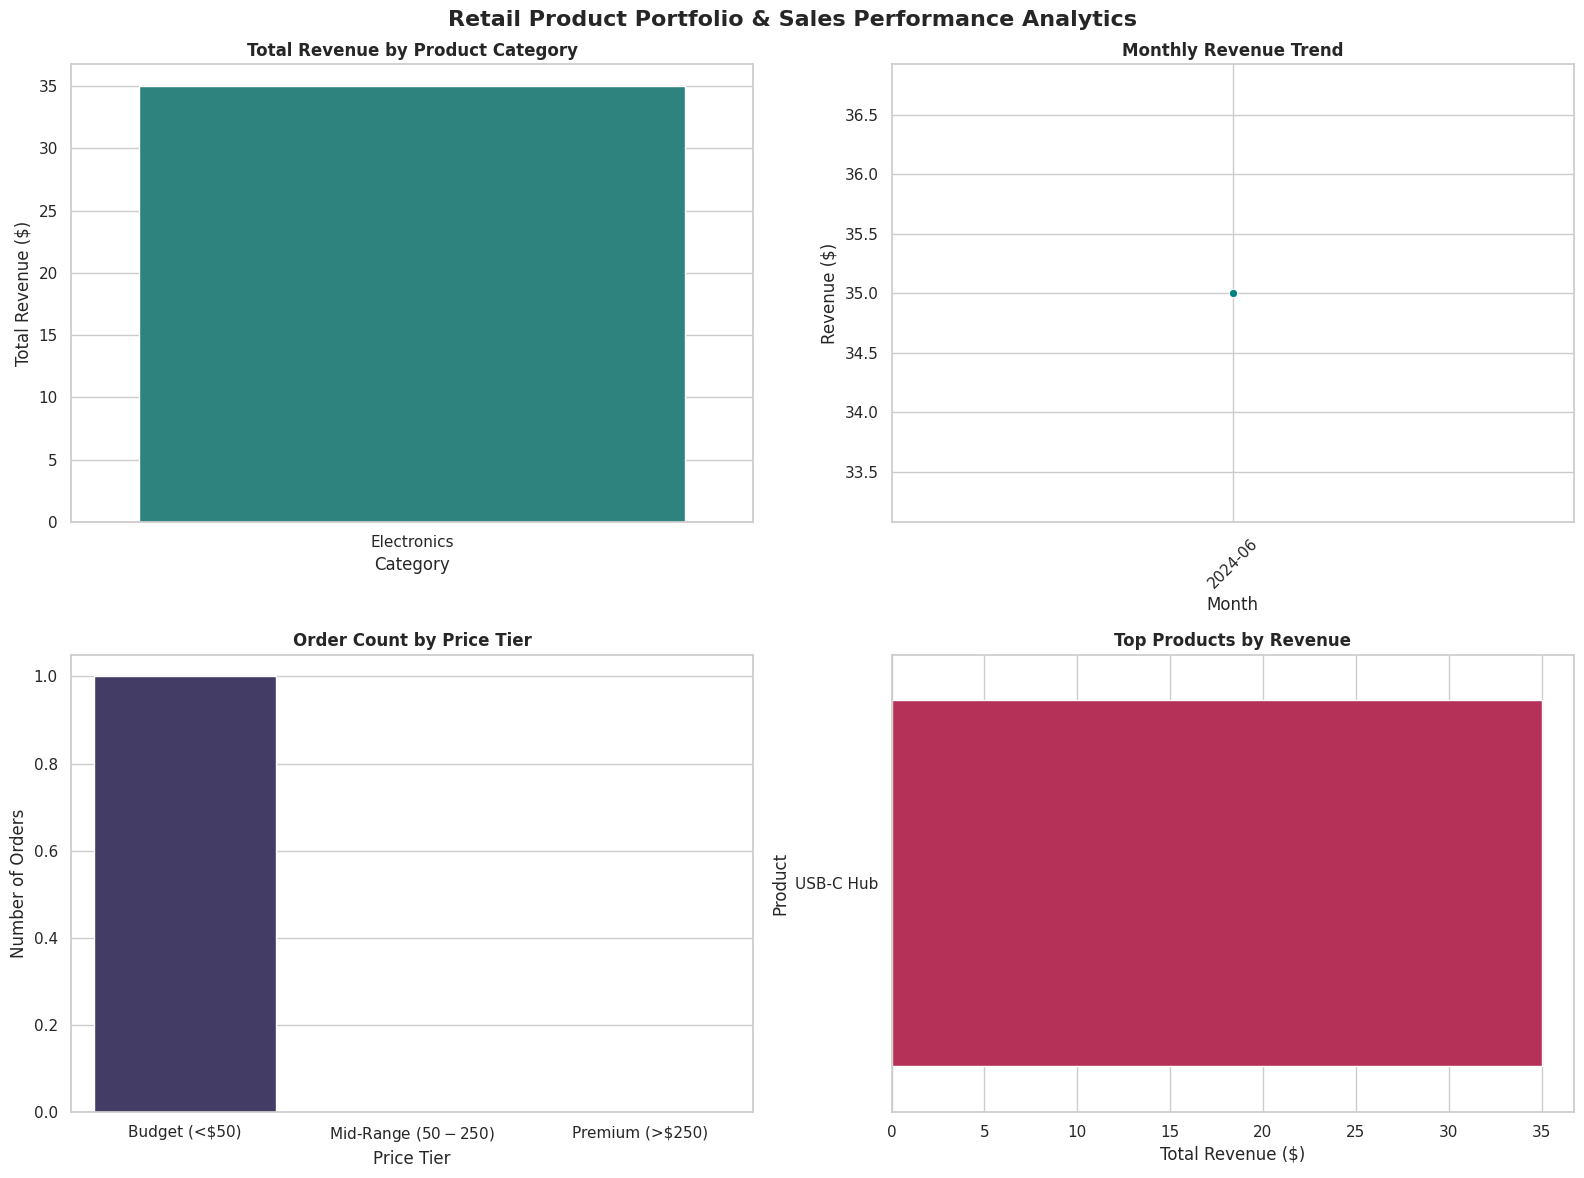

In [42]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Retail Product Portfolio & Sales Performance Analytics', fontsize=16, fontweight='bold')

# 1. Total Revenue by Product Category
sns.barplot(data=cat_summary.reset_index(), x='Category', y='Total_Revenue', hue='Category', ax=axes[0, 0], palette='viridis', legend=False)
axes[0, 0].set_title('Total Revenue by Product Category', fontweight='bold')
axes[0, 0].set_ylabel('Total Revenue ($)')
axes[0, 0].set_xlabel('Category')

# 2. Sales Trend Over Time
trend_df = df.groupby('YearMonth')['Revenue'].sum().reset_index().sort_values('YearMonth')
sns.lineplot(data=trend_df, x='YearMonth', y='Revenue', marker='o', color='teal', ax=axes[0, 1])
axes[0, 1].set_title('Monthly Revenue Trend', fontweight='bold')
axes[0, 1].set_ylabel('Revenue ($)')
axes[0, 1].set_xlabel('Month')
axes[0, 1].tick_params(axis='x', rotation=45)

# 3. Distribution by Price Tier
tier_counts = df['Price_Tier'].value_counts().reset_index()
sns.barplot(data=tier_counts, x='Price_Tier', y='count', hue='Price_Tier', ax=axes[1, 0], palette='mako', legend=False)
axes[1, 0].set_title('Order Count by Price Tier', fontweight='bold')
axes[1, 0].set_ylabel('Number of Orders')
axes[1, 0].set_xlabel('Price Tier')

# 4. Top 5 Products by Revenue
top_prods = prod_summary.head(5)
sns.barplot(data=top_prods, x='Total_Revenue', y='Product_Name', hue='Product_Name', ax=axes[1, 1], palette='rocket', legend=False)
axes[1, 1].set_title('Top Products by Revenue', fontweight='bold')
axes[1, 1].set_xlabel('Total Revenue ($)')
axes[1, 1].set_ylabel('Product')

plt.tight_layout()
plt.show()

In [40]:
sns.barplot(data=cat_summary.reset_index(), x='Category', y='Total_Revenue', hue='Category', ax=axes[0, 0], palette='viridis', legend=False)
axes[0, 0].set_title('Total Revenue by Product Category')
axes[0, 0].set_ylabel('Total Revenue ($)')

Text(4.444444444444459, 0.5, 'Total Revenue ($)')

In [45]:
top_10 = prod_summary.head(10)
sns.barplot(data=top_10, y='Product_Name', x='Total_Revenue', hue='ABC_Class', dodge=False, ax=axes[0, 1])
axes[0, 1].set_title('Top 10 Revenue-Generating Products (ABC Segmentation)')
axes[0, 1].set_xlabel('Total Revenue ($)')
axes[0, 1].set_ylabel('')

Text(838.8125, 0.5, '')

In [46]:
monthly_trends = df.groupby(['YearMonth', 'Category'])['Revenue'].sum().reset_index()
sns.lineplot(data=monthly_trends, x='YearMonth', y='Revenue', hue='Category', marker='o', ax=axes[1, 0])
axes[1, 0].set_title('Monthly Revenue Trends Across Categories')
axes[1, 0].tick_params(axis='x', rotation=45)
axes[1, 0].set_ylabel('Monthly Revenue ($)')
# Show every 3rd month label for readability
for idx, label in enumerate(axes[1, 0].get_xticklabels()):
    if idx % 3 != 0: label.set_visible(False)

In [48]:
tier_summary = df.groupby('Price_Tier', observed=False).agg(Total_Revenue=('Revenue', 'sum'), Total_Units=('Quantity', 'sum')).reset_index()
sns.barplot(data=tier_summary, x='Price_Tier', y='Total_Revenue', hue='Price_Tier', ax=axes[1, 1], palette='magma', legend=False)
axes[1, 1].set_title('Revenue Contribution by Product Price Tier')
axes[1, 1].set_ylabel('Total Revenue ($)')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

<Figure size 1200x600 with 0 Axes>

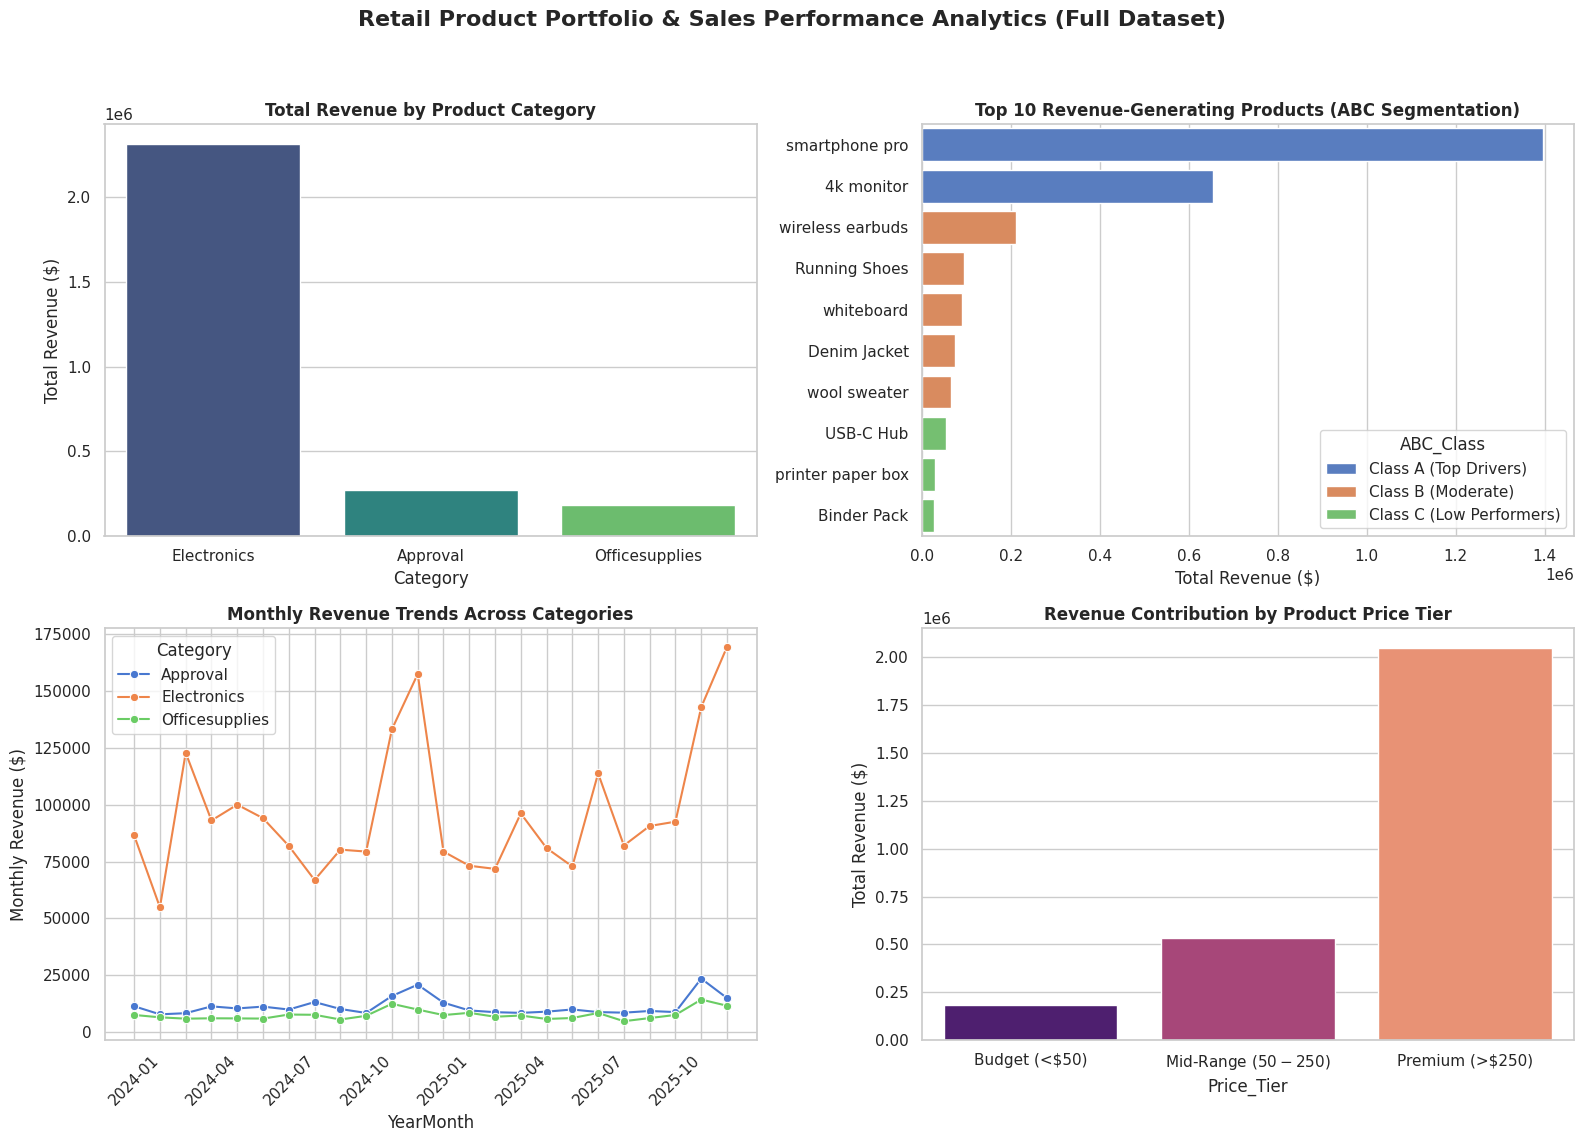

In [49]:
# 1. Rebuild DataFrame from the populated records list
df = pd.DataFrame(records, columns=['Order_ID', 'Order_Date', 'Category', 'Product_Name', 'Unit_Price', 'Quantity', 'Discount', 'Revenue'])
df['Order_Date'] = pd.to_datetime(df['Order_Date'])
df['YearMonth'] = df['Order_Date'].dt.to_period('M').astype(str)
df['Price_Tier'] = pd.cut(df['Unit_Price'], bins=[0, 50, 250, 2000], labels=['Budget (<$50)', 'Mid-Range ($50-$250)', 'Premium (>$250)'])

# 2. Recompute Category and Product Performance Summaries
cat_summary = df.groupby('Category').agg(
    Total_Revenue=('Revenue', 'sum'),
    Total_Quantity=('Quantity', 'sum'),
    Avg_Order_Value=('Revenue', 'mean'),
    Order_Count=('Order_ID', 'count')
).sort_values(by='Total_Revenue', ascending=False)

prod_summary = df.groupby(['Category', 'Product_Name']).agg(
    Total_Revenue=('Revenue', 'sum'),
    Total_Quantity=('Quantity', 'sum'),
    Avg_Price=('Unit_Price', 'mean')
).reset_index().sort_values(by='Total_Revenue', ascending=False)

prod_summary['Cum_Revenue'] = prod_summary['Total_Revenue'].cumsum()
prod_summary['Cum_Perc'] = 100 * prod_summary['Cum_Revenue'] / prod_summary['Total_Revenue'].sum()
prod_summary['ABC_Class'] = prod_summary['Cum_Perc'].apply(assign_abc)

# 3. Render the Complete Dashboard
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Retail Product Portfolio & Sales Performance Analytics (Full Dataset)', fontsize=16, fontweight='bold')

# Top-Left: Revenue by Category
sns.barplot(data=cat_summary.reset_index(), x='Category', y='Total_Revenue', hue='Category', ax=axes[0, 0], palette='viridis', legend=False)
axes[0, 0].set_title('Total Revenue by Product Category', fontweight='bold')
axes[0, 0].set_ylabel('Total Revenue ($)')

# Top-Right: Top 10 Revenue-Generating Products
top_10 = prod_summary.head(10)
sns.barplot(data=top_10, y='Product_Name', x='Total_Revenue', hue='ABC_Class', dodge=False, ax=axes[0, 1])
axes[0, 1].set_title('Top 10 Revenue-Generating Products (ABC Segmentation)', fontweight='bold')
axes[0, 1].set_xlabel('Total Revenue ($)')
axes[0, 1].set_ylabel('')

# Bottom-Left: Monthly Trends
monthly_trends = df.groupby(['YearMonth', 'Category'])['Revenue'].sum().reset_index().sort_values('YearMonth')
sns.lineplot(data=monthly_trends, x='YearMonth', y='Revenue', hue='Category', marker='o', ax=axes[1, 0])
axes[1, 0].set_title('Monthly Revenue Trends Across Categories', fontweight='bold')
axes[1, 0].set_ylabel('Monthly Revenue ($)')
axes[1, 0].tick_params(axis='x', rotation=45)
for idx, label in enumerate(axes[1, 0].get_xticklabels()):
    if idx % 3 != 0: label.set_visible(False)

# Bottom-Right: Revenue Contribution by Price Tier
tier_summary = df.groupby('Price_Tier', observed=False).agg(Total_Revenue=('Revenue', 'sum')).reset_index()
sns.barplot(data=tier_summary, x='Price_Tier', y='Total_Revenue', hue='Price_Tier', ax=axes[1, 1], palette='magma', legend=False)
axes[1, 1].set_title('Revenue Contribution by Product Price Tier', fontweight='bold')
axes[1, 1].set_ylabel('Total Revenue ($)')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()